In [525]:
import polars as pl
import requests
import matplotlib.pyplot as plt
import numpyro
import jax
from tqdm import tqdm

# Get data

In [526]:
url = "https://statsapi.mlb.com/api/v1/schedule?sportId=1&season=2026&gameType=R"
data = requests.get(url).json()

In [527]:
rows = []
for date_chunk in data["dates"]:
    date = date_chunk["date"]
    for game_data in date_chunk["games"]:
        try:
            home = game_data["teams"]["home"]["team"]["name"]
            away = game_data["teams"]["away"]["team"]["name"]
            home_wins = game_data["teams"]["home"]["isWinner"]
            rows.append({"date": date, "home": home, "away": away, "home_wins": home_wins})
        except KeyError: # Happens for postponed games
            continue
game_df = pl.DataFrame(rows)

In [528]:
game_df

date,home,away,home_wins
str,str,str,bool
"""2026-03-25""","""San Francisco Giants""","""New York Yankees""",false
"""2026-03-26""","""New York Mets""","""Pittsburgh Pirates""",true
"""2026-03-26""","""Milwaukee Brewers""","""Chicago White Sox""",true
"""2026-03-26""","""Chicago Cubs""","""Washington Nationals""",false
"""2026-03-26""","""Baltimore Orioles""","""Minnesota Twins""",true
…,…,…,…
"""2026-09-27""","""Seattle Mariners""","""Los Angeles Angels""",true
"""2026-09-27""","""Minnesota Twins""","""Texas Rangers""",true
"""2026-09-27""","""Chicago White Sox""","""Colorado Rockies""",true


In [590]:
home_wins = game_df.group_by(pl.col("home").alias("team")).agg(pl.col("home_wins").sum())
away_wins = (
    game_df
    .group_by(pl.col("away").alias("team"))
    .agg((~pl.col("home_wins").alias("away_wins")).sum())
)
wins = (
    home_wins
    .join(away_wins, on="team")
    .with_columns((pl.col("home_wins") + pl.col("away_wins")).alias("wins"))
    .sort("wins", descending=True)
)
with pl.Config(tbl_rows=10000):
    display(wins)

team,home_wins,away_wins,wins
str,u32,u32,u32
"""Milwaukee Brewers""",55,48,103
"""Los Angeles Dodgers""",51,49,100
"""Tampa Bay Rays""",55,43,98
"""Atlanta Braves""",52,42,94
"""New York Yankees""",46,47,93
"""San Diego Padres""",51,40,91
"""Chicago Cubs""",46,43,89
"""Philadelphia Phillies""",43,45,88
"""Boston Red Sox""",41,46,87


# Very simple modelling

In [530]:
from sklearn.linear_model import LogisticRegression, LinearRegression

In [586]:
preds = (
    game_df["home"].alias("").to_dummies(separator="").select(pl.all().cast(pl.Int64)) 
    - game_df["away"].alias("").to_dummies(separator="").select(pl.all().cast(pl.Int64))
)
model = LogisticRegression(fit_intercept=True, C=1e9).fit(preds, game_df["home_wins"])

In [587]:
1 / (1 + np.exp(-model.intercept_[0]))

np.float64(0.5293921145256613)

In [591]:
skills = (
    pl.DataFrame({"team": preds.columns, "coef": model.coef_[0]}).sort("coef", descending=True)
    .join(wins.select("team", "wins"), on="team")
)
with pl.Config(tbl_rows=-1):
    display(skills)

team,coef,wins
str,f64,u32
"""Milwaukee Brewers""",0.569588,103
"""Los Angeles Dodgers""",0.462265,100
"""Tampa Bay Rays""",0.41937,98
"""Atlanta Braves""",0.323998,94
"""New York Yankees""",0.311018,93
"""San Diego Padres""",0.248488,91
"""Chicago Cubs""",0.23442,89
"""Philadelphia Phillies""",0.19423,88
"""Boston Red Sox""",0.16096,87


In [534]:
worst_matchup = 1 / (1 + np.exp(skills["coef"].min() - skills["coef"].max()))
print(f"In most lopsided matchup, the favourite has a {worst_matchup * 100:.1f}% win probability")

In most lopsided matchup, the favourite has a 75.2% win probability


In [535]:
lin_model = LinearRegression(fit_intercept=True).fit(skills.select("coef"), skills["wins"])
beta = lin_model.coef_[0]
print(f"+0.1 skill corresponds to +{beta / 10:.2f} wins")
predictions = lin_model.predict(skills.select("coef"))
skills = (
    skills
    .with_columns(pl.Series(predictions).alias("predicted_wins"))
    .with_columns((pl.col("wins") - pl.col("predicted_wins")).alias("excess_wins"))
)                       

+0.1 skill corresponds to +3.89 wins


In [536]:
with pl.Config(tbl_rows=100):
    display(skills.sort("excess_wins", descending=True))

team,coef,wins,predicted_wins,excess_wins
str,f64,u32,f64,f64
"""Houston Astros""",-0.080181,81,77.877419,3.122581
"""Texas Rangers""",-0.089653,80,77.508566,2.491434
"""Seattle Mariners""",-0.183169,76,73.86664,2.13336
"""Cleveland Guardians""",0.053981,85,83.102223,1.897777
"""Athletics""",-0.480561,64,62.285025,1.714975
"""Chicago White Sox""",0.039319,84,82.531249,1.468751
"""Los Angeles Dodgers""",0.462265,100,99.002471,0.997529
"""Los Angeles Angels""",-0.513235,62,61.01256,0.98744
"""Detroit Tigers""",-0.151026,76,75.118432,0.881568


In [537]:
league_configs = pl.DataFrame([
    {"team": "Tampa Bay Rays", "league": "American", "division": "East", "short_name": "Rays"},
    {"team": "New York Yankees", "league": "American", "division": "East", "short_name": "Yankees"},
    {"team": "Boston Red Sox", "league": "American", "division": "East", "short_name": "Red Sox"},
    {"team": "Baltimore Orioles", "league": "American", "division": "East", "short_name": "Orioles"},
    {"team": "Toronto Blue Jays", "league": "American", "division": "East", "short_name": "Blue Jays"},
    {"team": "Cleveland Guardians", "league": "American", "division": "Central", "short_name": "Guardians"},
    {"team": "Chicago White Sox", "league": "American", "division": "Central", "short_name": "White Sox"},
    {"team": "Minnesota Twins", "league": "American", "division": "Central", "short_name": "Twins"},
    {"team": "Detroit Tigers", "league": "American", "division": "Central", "short_name": "Tigers"},
    {"team": "Kansas City Royals", "league": "American", "division": "Central", "short_name": "Royals"},
    {"team": "Houston Astros", "league": "American", "division": "West", "short_name": "Astros"},
    {"team": "Texas Rangers", "league": "American", "division": "West", "short_name": "Rangers"},
    {"team": "Seattle Mariners", "league": "American", "division": "West", "short_name": "Mariners"},
    {"team": "Athletics", "league": "American", "division": "West", "short_name": "Athletics"},
    {"team": "Los Angeles Angels", "league": "American", "division": "West", "short_name": "Angels"},
    {"team": "Atlanta Braves", "league": "National", "division": "East", "short_name": "Braves"},
    {"team": "Philadelphia Phillies", "league": "National", "division": "East", "short_name": "Phillies"},
    {"team": "Miami Marlins", "league": "National", "division": "East", "short_name": "Marlins"},
    {"team": "Washington Nationals", "league": "National", "division": "East", "short_name": "Nationals"},
    {"team": "New York Mets", "league": "National", "division": "East", "short_name": "Mets"},
    {"team": "Milwaukee Brewers", "league": "National", "division": "Central", "short_name": "Brewers"},
    {"team": "Chicago Cubs", "league": "National", "division": "Central", "short_name": "Cubs"},
    {"team": "Pittsburgh Pirates", "league": "National", "division": "Central", "short_name": "Pirates"},
    {"team": "St. Louis Cardinals", "league": "National", "division": "Central", "short_name": "Cardinals"},
    {"team": "Cincinnati Reds", "league": "National", "division": "Central", "short_name": "Reds"},
    {"team": "Los Angeles Dodgers", "league": "National", "division": "West", "short_name": "Dodgers"},
    {"team": "San Diego Padres", "league": "National", "division": "West", "short_name": "Padres"},
    {"team": "Arizona Diamondbacks", "league": "National", "division": "West", "short_name": "Diamondbacks"},
    {"team": "San Francisco Giants", "league": "National", "division": "West", "short_name": "Giants"},
    {"team": "Colorado Rockies", "league": "National", "division": "West", "short_name": "Rockies"},
])
skills = skills.join(league_configs, on="team")

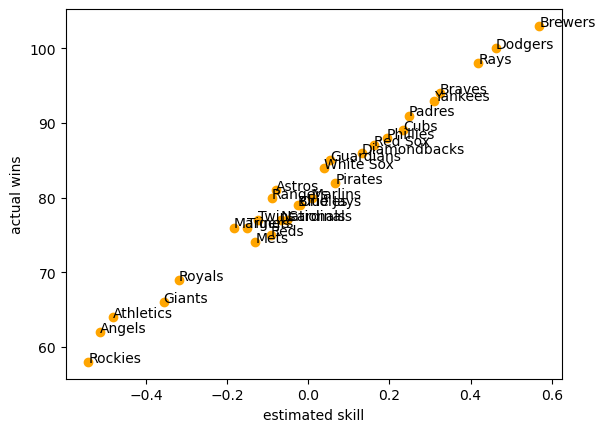

In [575]:
fig, ax = plt.subplots()
ax.scatter(skills["coef"], skills["wins"], color="orange")
for row in skills.iter_rows(named=True):
    ax.text(row["coef"], row["wins"], row["short_name"])
ax.set_xlabel("estimated skill")
ax.set_ylabel("actual wins")
plt.show()

In [539]:
skills.group_by("league", "division").agg(pl.col("excess_wins").mean()).sort("excess_wins", descending=True)

league,division,excess_wins
str,str,f64
"""American""","""West""",2.089958
"""American""","""Central""",1.09174
"""National""","""West""",-0.369045
"""American""","""East""",-0.376727
"""National""","""East""",-0.972823
"""National""","""Central""",-1.463103


In [540]:
skills.group_by("league", "division").agg(pl.col("coef").mean()).sort("coef", descending=True)

league,division,coef
str,str,f64
"""American""","""East""",0.168876
"""National""","""Central""",0.145416
"""National""","""East""",0.066065
"""National""","""West""",-0.011066
"""American""","""Central""",-0.099932
"""American""","""West""",-0.26936


Note it says the AL East is the most talented league, but being put in NL Central takes more off your expected wins, given your skill. The difference is that if you're in NL Central you have easier within-division games, but harder within-league-but-outside-division play. So although the Orioles have to play the Yankees, Rays, and Red Sox more often, they also get to beat up on the AL West and Central. 

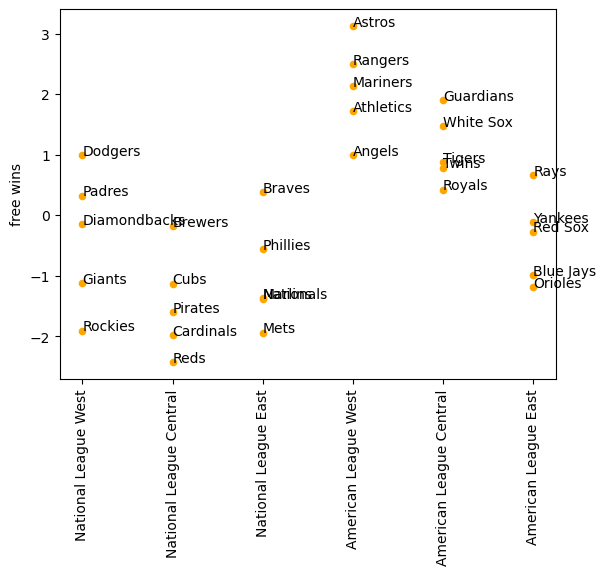

In [541]:
fig, ax = plt.subplots()
mapping = {
    "American League East": 5,
    "American League Central": 4,
    "American League West": 3,
    "National League East": 2,
    "National League Central": 1,
    "National League West": 0,
}
# jitter = np.random.normal(0, 0.05, skills.height)
ax.scatter(
    (skills["league"] + " League " + skills["division"]).replace_strict(mapping),# + jitter, 
    skills["excess_wins"], 
    color="orange", 
    s=20
)
for row in skills.iter_rows(named=True):
    ax.text(
        mapping[row["league"] + " League " + row["division"]],
        row["excess_wins"], 
        row["short_name"],
        color="black",
    )
ax.set_xticks(pl.Series(mapping.values()))
ax.set_xticklabels(mapping.keys(), rotation=90)
ax.set_ylabel("free wins")
plt.show()

Note this is a bit unfair: your being good and winning games makes the model think your opponents sucked, and therefore you had an easier draw, and so you're not as good as your wins make you out to be. Also it doesn't capture other important things like uhh priors, also we want a strict measure of uncertainty. 

# Bayesian time

The model:
* Team skills are $\text{Normal}(0, \sigma^2)$
* Home field advantage is $\text{Normal}(0.05, 0.05)$
* The stdev for team skills is $\sigma \sim \text{Exponential}(0.5)$

When two teams play each other, $P(\text{home wins}) = \text{inverse logit}(\text{home skill} - \text{away skill} + \text{home advantage})$, where $\text{inverse logit}(x) = \frac{1}{1 + e^{-x}}$

## Write the model

In [542]:
team_encoding = {team: i for i, team in enumerate(game_df["home"].unique().sort())}
team_decoding = {i: team for team, i in team_encoding.items()}
game_df = game_df.with_columns(
    pl.col("home").replace_strict(team_encoding).alias("home_code"),
    pl.col("away").replace_strict(team_encoding).alias("away_code"),
)

home_codes = jax.numpy.array(game_df["home_code"].to_numpy())
away_codes = jax.numpy.array(game_df["away_code"].to_numpy())
results = jax.numpy.array(game_df["home_wins"].to_numpy(), dtype=jax.numpy.int32)

In [543]:
def model(home_codes, away_codes, results, n_teams=30):
    home_advantage = numpyro.sample("home_advantage", numpyro.distributions.Normal(0.05, 0.05))
    team_sigma = numpyro.sample("team_sigma", numpyro.distributions.Exponential(4.0)) # rate is 4.0, mean is 0.25
    skills = numpyro.sample("skills", numpyro.distributions.Normal(0, team_sigma).expand([n_teams]))
    logits = skills[home_codes] - skills[away_codes] + home_advantage
    numpyro.sample("winner", numpyro.distributions.Bernoulli(logits=logits), obs=results)

## Prior predictive checking

(Tuned this a bit so the check looks good)

In [544]:
predictive = numpyro.infer.Predictive(model, num_samples=500)
prior_samples = predictive(
    jax.random.PRNGKey(1),
    home_codes=home_codes,
    away_codes=away_codes,
    results=None,
)

simulated_results = prior_samples['winner']

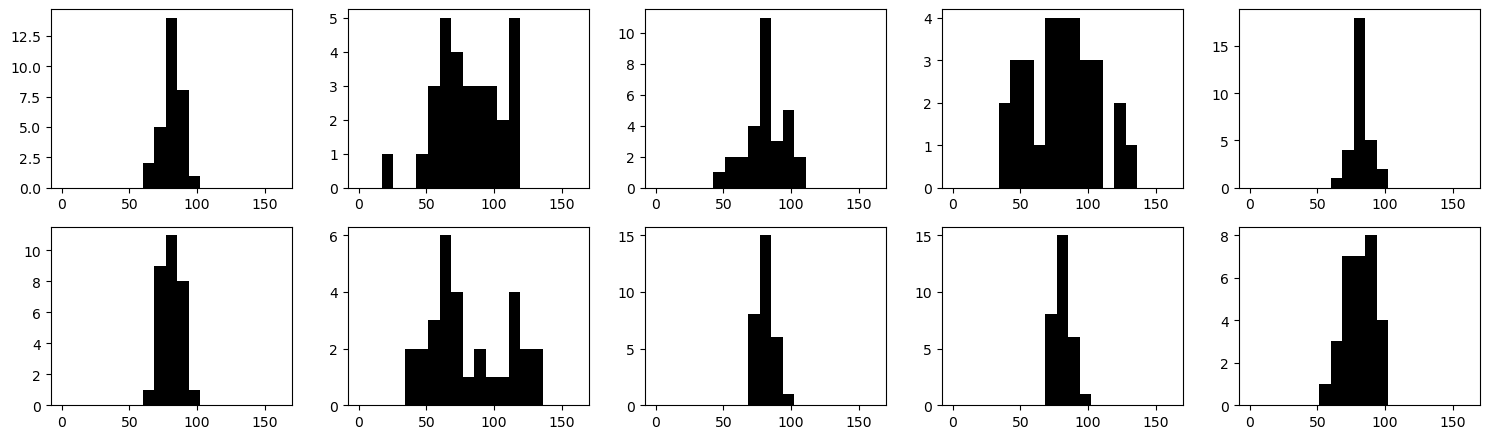

In [545]:
# Take one random season
fig, ax = plt.subplots(ncols=5, nrows=2, figsize=(15, 4.5))
for i, season_num in enumerate(range(100, 110)):
    t = game_df.with_columns(pl.Series(np.array(simulated_results[season_num,:])).alias("result"))
    standings = (
        t.group_by(pl.col("home").alias("team")).agg(pl.col("result").sum().alias("home_wins"))
        .join(t.group_by(pl.col("away").alias("team")).agg((1 - pl.col("result")).sum().alias("away_wins")), on="team")
        .with_columns((pl.col("home_wins") + pl.col("away_wins")).alias("wins"))
        .sort("wins", descending=True)
    )
    ax.flatten()[i].hist(standings["wins"], bins=np.linspace(0, 162, 20), color="black")
# print(f"frac home wins: {t['result'].mean():.2f}")
# standings
plt.tight_layout()
plt.show()

Ehhh looks about alright, not ideal, but priors are allowed to be loose. 

## Calibration checking

In [546]:
true_params = numpyro.infer.Predictive(model, num_samples=1)(
    jax.random.PRNGKey(723),
    home_codes=home_codes,
    away_codes=away_codes,
    results=None,
)
sim_y = true_params['winner'][0]

In [547]:
mcmc = numpyro.infer.MCMC(numpyro.infer.NUTS(model), num_warmup=500, num_samples=1000)
mcmc.run(
    jax.random.PRNGKey(1),
    home_codes=home_codes,
    away_codes=away_codes,
    results=sim_y,
)
posterior = mcmc.get_samples()

sample: 100%|█| 1500/1500 [00:01<00:00, 838.77it/s, 7 steps of size 4.84e-01. ac


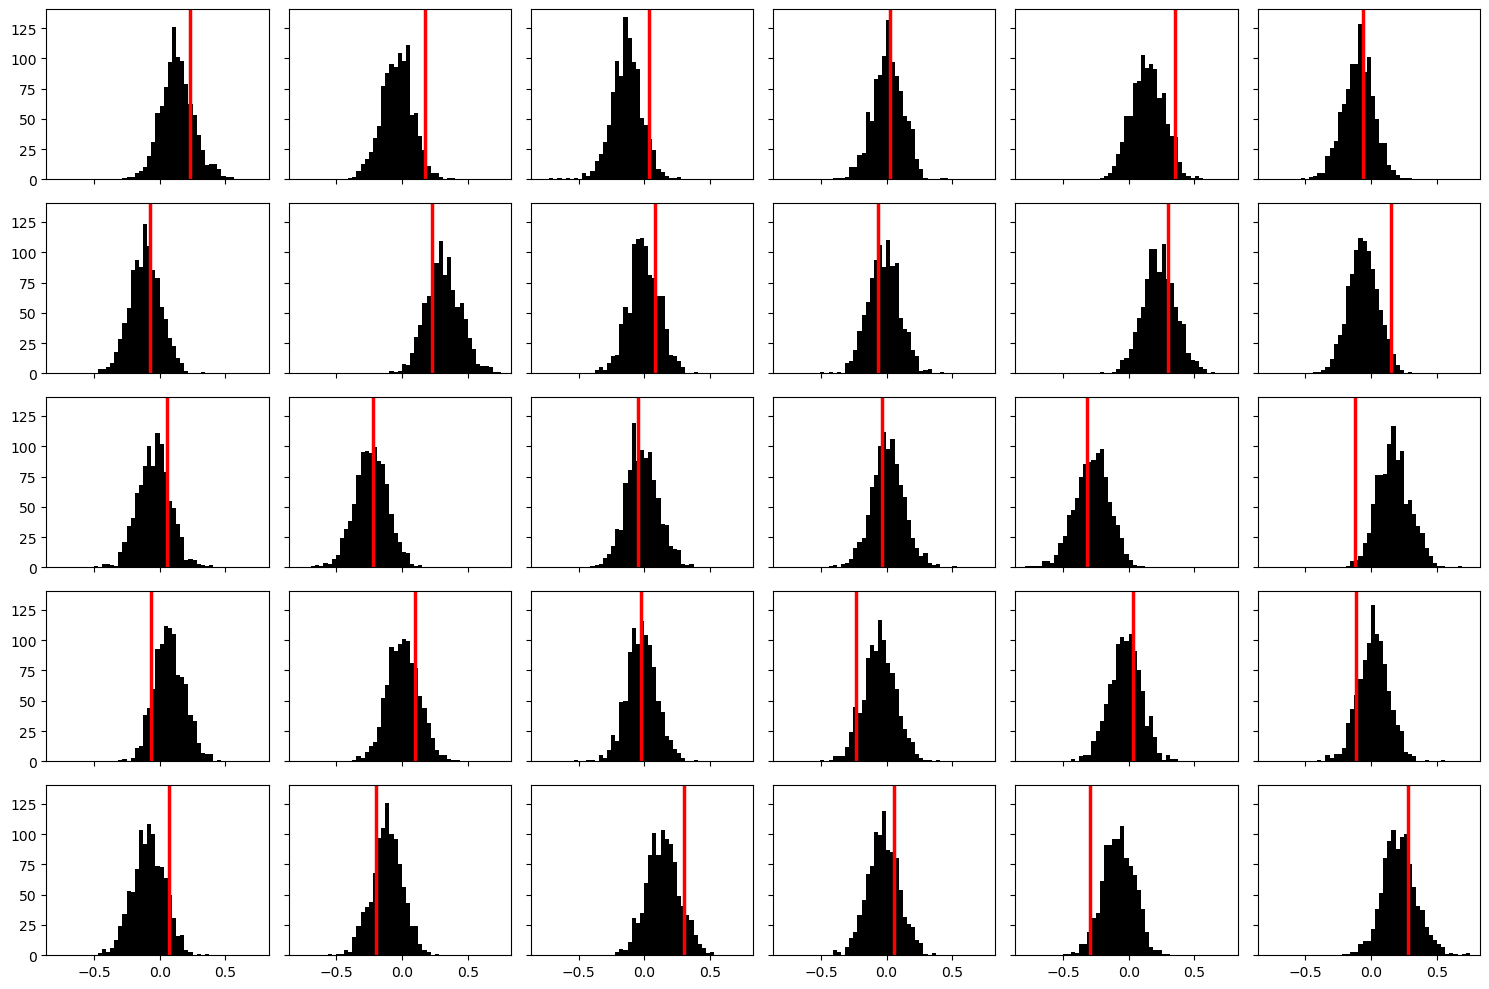

In [548]:
fig, ax = plt.subplots(ncols=6, nrows=5, figsize=(15, 10), sharex=True, sharey=True)
bins = np.linspace(posterior["skills"].min(), posterior["skills"].max(), 50)
for i in range(30):
    ax.flatten()[i].hist(posterior["skills"][:,i], bins=bins, color="black")
    ax.flatten()[i].axvline(true_params["skills"][0,i], color="red", linewidth=2.5)
plt.tight_layout()
plt.show()

Looks good enough. 

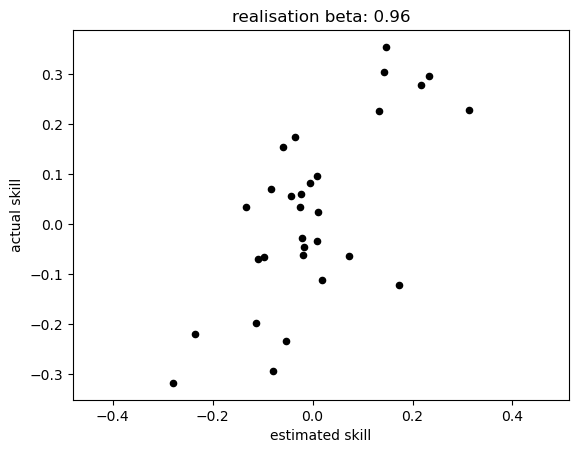

In [549]:
fig, ax = plt.subplots()
estimates = posterior["skills"].mean(axis=0)
actual = true_params["skills"][0]
ax.scatter(estimates, actual, s=20, color="black")
ax.set_xlabel("estimated skill")
ax.set_ylabel("actual skill")
plt.axis("equal")
beta = (estimates * actual).sum() / (estimates ** 2).sum()
ax.set_title(f"realisation beta: {beta:.2f}")
plt.show()

Looks pretty good

## Fit the model

In [550]:
kernel = numpyro.infer.NUTS(model)
mcmc = numpyro.infer.MCMC(kernel, num_warmup=500, num_samples=1000)
mcmc.run(jax.random.PRNGKey(0), home_codes=home_codes, away_codes=away_codes, results=results)
mcmc.print_summary()

sample: 100%|█| 1500/1500 [00:01<00:00, 841.49it/s, 15 steps of size 4.24e-01. a


                      mean       std    median      5.0%     95.0%     n_eff     r_hat
  home_advantage      0.09      0.03      0.09      0.04      0.14   1644.76      1.00
       skills[0]      0.08      0.13      0.08     -0.13      0.28    996.49      1.00
       skills[1]     -0.30      0.13     -0.30     -0.54     -0.11    780.57      1.00
       skills[2]      0.20      0.13      0.20     -0.02      0.42    995.35      1.00
       skills[3]     -0.02      0.14     -0.02     -0.26      0.21   1377.78      1.00
       skills[4]      0.10      0.13      0.10     -0.11      0.31    850.26      1.00
       skills[5]      0.15      0.14      0.14     -0.09      0.35   1168.51      1.00
       skills[6]      0.04      0.14      0.04     -0.17      0.29    880.60      1.00
       skills[7]     -0.07      0.13     -0.07     -0.28      0.13    863.56      1.00
       skills[8]      0.05      0.14      0.05     -0.18      0.28   1185.14      1.00
       skills[9]     -0.36      0.14     -

Nice fit, all rhats are 1 (cool trick to get rhat 1: use only one chain), no divergences

## Analysis

In [551]:
bayes_skills = pl.DataFrame({team: np.array(mcmc.get_samples()["skills"])[:,i] for i, team in team_decoding.items()})
mean_skills = (
    bayes_skills
    .mean()
    .transpose(include_header=True)
    .sort("column_0", descending=True)
    .rename({"column": "team", "column_0": "skill_mean"})
)
with pl.Config(tbl_rows=30):
    display(mean_skills)

team,skill_mean
str,f32
"""Milwaukee Brewers""",0.365875
"""Los Angeles Dodgers""",0.301061
"""Tampa Bay Rays""",0.274823
"""New York Yankees""",0.20642
"""Atlanta Braves""",0.204651
"""San Diego Padres""",0.163077
"""Chicago Cubs""",0.146149
"""Philadelphia Phillies""",0.118419
"""Boston Red Sox""",0.103231


Note the stdev is about 0.14 for teams. Makes sense that the Brewers are teh best and the Rockies are the worst. 

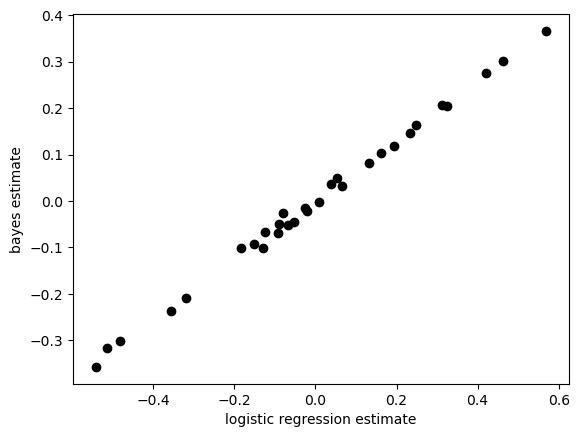

In [552]:
# Compare to earlier
fig, ax = plt.subplots()
ax.scatter(skills.sort("team")["coef"], mean_skills.sort("team")["skill_mean"], color="black")
ax.set_xlabel("logistic regression estimate")
ax.set_ylabel("bayes estimate")
plt.show()

In [579]:
a, b = skills.sort("team")["coef"], mean_skills.sort("team")["skill_mean"]
(a * b).sum() / a.pow(2).sum() # beta

0.6421305893381443

Not much changed, which is reassuring

In [553]:
# P(Brewers are best team)
(bayes_skills.max_horizontal() == bayes_skills["Milwaukee Brewers"]).mean()

0.397

In [554]:
# P(Brewers > Dodgers)
(bayes_skills["Milwaukee Brewers"] > bayes_skills["Los Angeles Dodgers"]).mean()

0.626

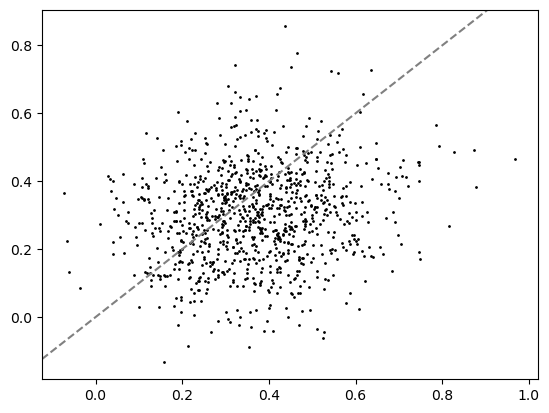

In [555]:
fig, ax = plt.subplots()
ax.scatter(bayes_skills["Milwaukee Brewers"], bayes_skills["Los Angeles Dodgers"], s=1, color="black")
ax.axline((0, 0), slope=1, color='gray', linestyle='--')
plt.show()

In [556]:
# P(Brewers > Rockies)
(bayes_skills["Milwaukee Brewers"] > bayes_skills["Colorado Rockies"]).mean()

1.0

In [557]:
# P(Brewers beat Rockies, ignore home advantage)
logits = bayes_skills["Milwaukee Brewers"] - bayes_skills["Colorado Rockies"]
np.random.binomial(1, 1 / (1 + np.exp(-logits))).mean().item()

0.672

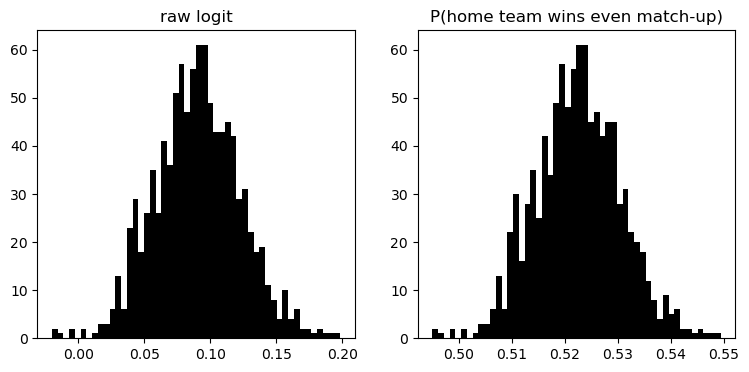

In [558]:
# Home advantage, note prior was Normal(mean=0.05, std=0.05)
fig, ax = plt.subplots(ncols=2, figsize=(9, 4))
ax[0].hist(mcmc.get_samples()["home_advantage"], bins=50, color="black")
ax[0].set_title("raw logit")
ax[1].hist(1 / (1 + np.exp(-np.array(mcmc.get_samples()["home_advantage"]))), bins=50, color="black")
ax[1].set_title("P(home team wins even match-up)")
plt.show()

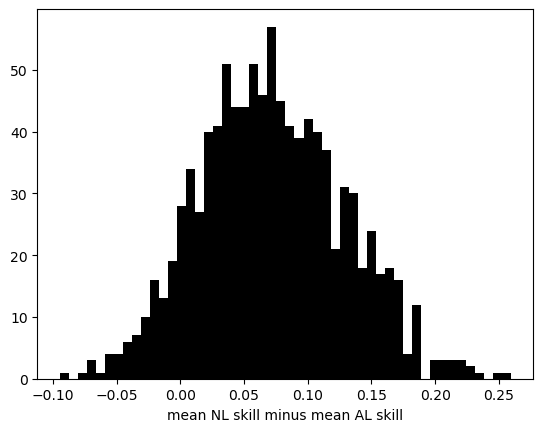

In [592]:
# The actual league differential
al_teams = league_configs.filter(pl.col("league") == "American")["team"].to_list()
nl_teams = league_configs.filter(pl.col("league") == "National")["team"].to_list()
diff = bayes_skills.select(nl_teams).mean_horizontal() - bayes_skills.select(al_teams).mean_horizontal()
fig, ax = plt.subplots()
ax.hist(diff, bins=50, color="black")
ax.set_xlabel("mean NL skill minus mean AL skill")
plt.show()

In [560]:
(diff > 0).mean(), 1 / (1 + np.exp(-diff.mean())).item()

(0.906, 0.5179675909956283)

Not that dramatic!! About the home field advantage, although a little smaller and with wider stdev. 

# Simulations

## Rerun the league

In [561]:
def get_sims(game_df):
    records = []
    for sim_num in tqdm(range(1000)):
        home_advantage = mcmc.get_samples()["home_advantage"][sim_num]
        team_skills = mcmc.get_samples()["skills"][sim_num]
        logit = team_skills[game_df["home_code"].to_numpy()] - team_skills[game_df["away_code"].to_numpy()] + home_advantage
        sim_df = game_df.with_columns(pl.Series(np.random.binomial(1, 1 / (1 + np.exp(-logit)))).alias("home_wins"))
        results = (
            sim_df.group_by(pl.col("home").alias("team")).agg(pl.col("home_wins").sum())
            .join(sim_df.group_by(pl.col("away").alias("team")).agg((1 - pl.col("home_wins")).alias("away_wins").sum()), on="team")
            .with_columns((pl.col("home_wins") + pl.col("away_wins")).alias("wins"))
            .join(league_configs, on="team")
        )
        league_winners = results.sort("wins", descending=True).unique(subset=["league", "division"], keep="first")
        rest = results.join(league_winners, on="team", how="anti").sort(["league", "wins"], descending=True)
        nl_wildcards = rest.filter(pl.col("league") == "National")[:3]
        al_wildcards = rest.filter(pl.col("league") == "American")[:3]
        summary = pl.concat([
            league_winners.select("team", pl.lit("league_winner").alias("status")),
            nl_wildcards.select("team", pl.lit("wildcard").alias("status")),
            al_wildcards.select("team", pl.lit("wildcard").alias("status")),
        ])
        losers = rest.join(summary, on="team", how="anti").select("team", pl.lit("eliminated").alias("status"))
        summary = pl.concat([summary, losers])
        records.append(summary)
    return pl.concat(records)

In [562]:
combined_records = get_sims(game_df)
rows = []
for team in combined_records["team"].unique():
    results = combined_records.filter(pl.col("team") == team)["status"].value_counts()
    rows.append({"team": team} | dict(zip(results["status"], results["count"])))
result_summary = (
    pl.DataFrame(rows)
    .select(
        "team",
        pl.col("league_winner").fill_null(0),
        pl.col("wildcard").fill_null(0),
        pl.col("eliminated").fill_null(0),
    )
    .with_columns((pl.col("league_winner") + pl.col("wildcard")).alias("p_postseason") / 1000)
    .sort("p_postseason", descending=True)
)

100%|██████████████████████████████████████| 1000/1000 [00:04<00:00, 207.56it/s]


In [563]:
result_summary

team,league_winner,wildcard,eliminated,p_postseason
str,i64,i64,i64,f64
"""Milwaukee Brewers""",679,204,117,0.883
"""Los Angeles Dodgers""",613,239,148,0.852
"""Tampa Bay Rays""",474,375,151,0.849
"""New York Yankees""",284,478,238,0.762
"""Atlanta Braves""",535,204,261,0.739
…,…,…,…,…
"""Kansas City Royals""",38,73,889,0.111
"""Athletics""",50,33,917,0.083
"""Los Angeles Angels""",34,26,940,0.06


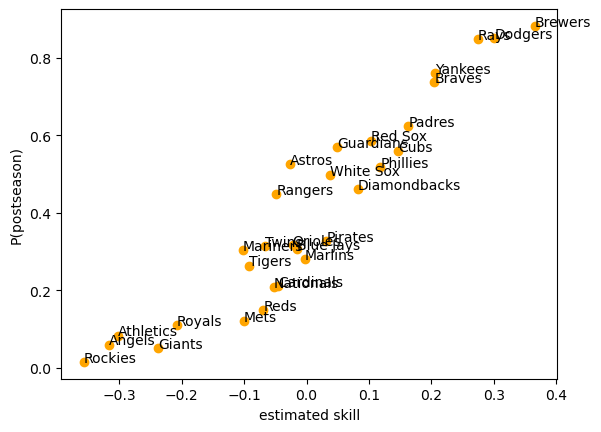

In [564]:
# Plot p_postseason against skill
fig, ax = plt.subplots()
s, p = mean_skills.sort("team")["skill_mean"], result_summary.sort("team")["p_postseason"]
ax.scatter(s, p, color="orange")
for name, skill, prob in zip(league_configs.sort("team")["short_name"], s, p):
    ax.text(skill, prob, name)
ax.set_xlabel("estimated skill")
ax.set_ylabel("P(postseason)")
plt.show()

Can see this looks pretty sigmoidal, and of course the ones with the biggest positive residual are the Astros. 

## Swap Mets and Astros

In [565]:
tweaked_game_df = game_df.with_columns(
    pl.col("home").replace({"New York Mets": "Houston Astros", "Houston Astros": "New York Mets"}),
    pl.col("away").replace({"New York Mets": "Houston Astros", "Houston Astros": "New York Mets"}),
)
tweaked_results = get_sims(tweaked_game_df)

100%|██████████████████████████████████████| 1000/1000 [00:04<00:00, 215.64it/s]


In [566]:
rows = []
for team in tweaked_results["team"].unique():
    results = tweaked_results.filter(pl.col("team") == team)["status"].value_counts()
    rows.append({"team": team} | dict(zip(results["status"], results["count"])))
tweaked_summary = (
    pl.DataFrame(rows)
    .select(
        "team",
        pl.col("league_winner").fill_null(0),
        pl.col("wildcard").fill_null(0),
        pl.col("eliminated").fill_null(0),
    )
    .with_columns((pl.col("league_winner") + pl.col("wildcard")).alias("p_postseason") / 1000)
    .sort("p_postseason", descending=True)
)

In [567]:
tweaked_summary.filter(pl.col("team").is_in(["New York Mets", "Houston Astros"]))

team,league_winner,wildcard,eliminated,p_postseason
str,i64,i64,i64,f64
"""New York Mets""",115,215,670,0.33
"""Houston Astros""",193,63,744,0.256


In [568]:
# Compare to...
result_summary.filter(pl.col("team").is_in(["New York Mets", "Houston Astros"]))

team,league_winner,wildcard,eliminated,p_postseason
str,i64,i64,i64,f64
"""Houston Astros""",413,113,474,0.526
"""New York Mets""",41,80,879,0.121


## Permute teams at random

In [569]:
records = []
astros_wins = []
for sim_num in tqdm(range(1000)):
    home_advantage = mcmc.get_samples()["home_advantage"][sim_num]
    team_skills = mcmc.get_samples()["skills"][sim_num]
    permutation = dict(zip(league_configs["team"], league_configs["team"].sample(fraction=1, shuffle=True)))
    permuted_df = (
        game_df
        .with_columns(
            pl.col("home").replace(permutation),
            pl.col("away").replace(permutation),
        ).with_columns(
            pl.col("home").replace_strict(team_encoding).alias("home_code"),
            pl.col("away").replace_strict(team_encoding).alias("away_code"),
        )
    )
    logit = team_skills[permuted_df["home_code"].to_numpy()] - team_skills[permuted_df["away_code"].to_numpy()] + home_advantage
    sim_df = permuted_df.with_columns(pl.Series(np.random.binomial(1, 1 / (1 + np.exp(-logit)))).alias("home_wins"))
    results = (
        sim_df.group_by(pl.col("home").alias("team")).agg(pl.col("home_wins").sum())
        .join(sim_df.group_by(pl.col("away").alias("team")).agg((1 - pl.col("home_wins")).alias("away_wins").sum()), on="team")
        .with_columns((pl.col("home_wins") + pl.col("away_wins")).alias("wins"))
        .join(league_configs.with_columns(pl.col("team").replace_strict(permutation)), on="team")
    )
    league_winners = results.sort("wins", descending=True).unique(subset=["league", "division"], keep="first")
    rest = results.join(league_winners, on="team", how="anti").sort(["league", "wins"], descending=True)
    nl_wildcards = rest.filter(pl.col("league") == "National")[:3]
    al_wildcards = rest.filter(pl.col("league") == "American")[:3]
    summary = pl.concat([
        league_winners.select("team", pl.lit("league_winner").alias("status")),
        nl_wildcards.select("team", pl.lit("wildcard").alias("status")),
        al_wildcards.select("team", pl.lit("wildcard").alias("status")),
    ])
    losers = rest.join(summary, on="team", how="anti").select("team", pl.lit("eliminated").alias("status"))
    summary = pl.concat([summary, losers])
    records.append(summary)
    astros_wins.append(results.filter(pl.col("team") == "Houston Astros")["wins"].item())
full_permuted_record = pl.concat(records)

100%|██████████████████████████████████████| 1000/1000 [00:06<00:00, 162.96it/s]


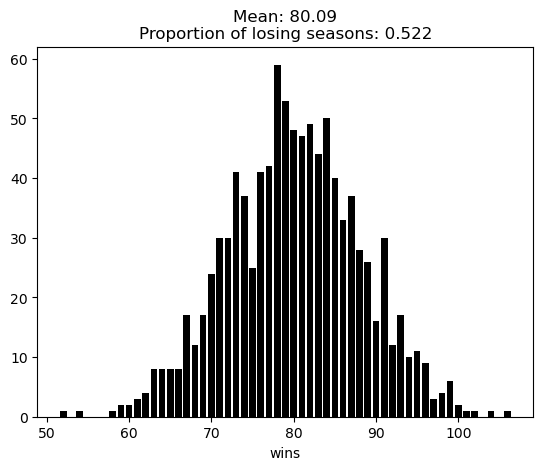

In [570]:
fig, ax = plt.subplots()
wins = pl.Series(astros_wins).alias("wins")
counts = wins.value_counts()
ax.bar(counts["wins"], counts["count"], color="black")
ax.set_xlabel("wins")
ax.set_title(f"Mean: {wins.mean():.2f}\nProportion of losing seasons: {(wins < 81).mean()}")
plt.show()

In [571]:
rows = []
for team in full_permuted_record["team"].unique():
    results = full_permuted_record.filter(pl.col("team") == team)["status"].value_counts()
    rows.append({"team": team} | dict(zip(results["status"], results["count"])))
permuted_summary = (
    pl.DataFrame(rows)
    .select(
        "team",
        pl.col("league_winner").fill_null(0),
        pl.col("wildcard").fill_null(0),
        pl.col("eliminated").fill_null(0),
    )
    .with_columns((pl.col("league_winner") + pl.col("wildcard")).alias("p_postseason") / 1000)
    .sort("p_postseason", descending=True)
)

In [572]:
with pl.Config(tbl_rows=100):
    display(permuted_summary)

team,league_winner,wildcard,eliminated,p_postseason
str,i64,i64,i64,f64
"""Milwaukee Brewers""",674,247,79,0.921
"""Los Angeles Dodgers""",570,287,143,0.857
"""Tampa Bay Rays""",530,303,167,0.833
"""Atlanta Braves""",420,316,264,0.736
"""New York Yankees""",403,320,277,0.723
"""San Diego Padres""",321,316,363,0.637
"""Chicago Cubs""",305,323,372,0.628
"""Philadelphia Phillies""",264,325,411,0.589
"""Boston Red Sox""",265,320,415,0.585


In [573]:
# Now compare
def logit(s): return (s / (1 - s)).log()
altogether = (
    result_summary.select("team", pl.col("p_postseason").alias("orthodox_p_postseason"))
    .join(permuted_summary.select("team", pl.col("p_postseason").alias("permuted_p_postseason")), on="team")
    .with_columns((pl.col("orthodox_p_postseason") - pl.col("permuted_p_postseason")).alias("diff"))
)
display(altogether.sort("diff", descending=True))

team,orthodox_p_postseason,permuted_p_postseason,diff
str,f64,f64,f64
"""Houston Astros""",0.526,0.335,0.191
"""Texas Rangers""",0.449,0.273,0.176
"""Cleveland Guardians""",0.569,0.461,0.108
"""Seattle Mariners""",0.303,0.223,0.08
"""Minnesota Twins""",0.315,0.254,0.061
…,…,…,…
"""Philadelphia Phillies""",0.519,0.589,-0.07
"""New York Mets""",0.121,0.198,-0.077
"""Cincinnati Reds""",0.149,0.25,-0.101


In [574]:
# Much clearer story here
altogether = altogether.with_columns(
    (logit(pl.col("orthodox_p_postseason")) - logit(pl.col("permuted_p_postseason"))).alias("logit_diff")
)
with pl.Config(tbl_rows=1000):
    display(altogether.join(league_configs, on="team").sort("logit_diff", descending=True))

team,orthodox_p_postseason,permuted_p_postseason,diff,logit_diff,league,division,short_name
str,f64,f64,f64,f64,str,str,str
"""Houston Astros""",0.526,0.335,0.191,0.78975,"""American""","""West""","""Astros"""
"""Texas Rangers""",0.449,0.273,0.176,0.774743,"""American""","""West""","""Rangers"""
"""Los Angeles Angels""",0.06,0.031,0.029,0.690742,"""American""","""West""","""Angels"""
"""Athletics""",0.083,0.051,0.032,0.521316,"""American""","""West""","""Athletics"""
"""Cleveland Guardians""",0.569,0.461,0.108,0.43409,"""American""","""Central""","""Guardians"""
"""Seattle Mariners""",0.303,0.223,0.08,0.415216,"""American""","""West""","""Mariners"""
"""Minnesota Twins""",0.315,0.254,0.061,0.300545,"""American""","""Central""","""Twins"""
"""Detroit Tigers""",0.264,0.221,0.043,0.234567,"""American""","""Central""","""Tigers"""
"""New York Yankees""",0.762,0.723,0.039,0.204284,"""American""","""East""","""Yankees"""


And the entire top 10 is the AL West and Central (well, if you ignore the Yankees)

In [583]:
(
    altogether
    .join(league_configs, on="team")
    .group_by("league", "division")
    .agg(pl.col("permuted_p_postseason").sum())
    .sort("permuted_p_postseason", descending=True)
)

league,division,permuted_p_postseason
str,str,f64
"""American""","""East""",2.826
"""National""","""Central""",2.544
"""National""","""East""",2.13
"""National""","""West""",2.104
"""American""","""Central""",1.483
"""American""","""West""",0.913


# Scratch